In [1]:
import sys

print(sys.executable)

e:\conda_envs\codementor\python.exe


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn


In [3]:
from pathlib import Path

BASE_DIR = Path.cwd().parent
DATA_DIR = BASE_DIR / "dataset" / "raw"

print("Project directory:", BASE_DIR)
print("Dataset directory:", DATA_DIR)

Project directory: e:\codeMentor\backend
Dataset directory: e:\codeMentor\backend\dataset\raw


In [4]:
questions_path = DATA_DIR / "tst_questions.csv"

print("File exists:", questions_path.exists())
print("File:", questions_path)

with open(questions_path, "r", encoding="utf-8", errors="replace") as f:
    for i in range(5):
        print(f"\nLine {i + 1}:")
        print(f.readline()[:1000])

File exists: True
File: e:\codeMentor\backend\dataset\raw\tst_questions.csv

Line 1:
"question"~"statement"~"tests"


Line 2:
"bst_height"~" # BST Height


Line 3:



Line 4:
    The height of a tree is the size of the longest path between the root and all the leaves.


Line 5:




In [5]:
# Load submissions
submissions = pd.read_csv(
    DATA_DIR / "java_submissions.csv"
)

# Load questions
questions = pd.read_csv(
    DATA_DIR / "tst_questions.csv",
    sep="~",
    quotechar='"',
    engine="python"
)

# Load distribution
distribution = pd.read_csv(
    DATA_DIR / "distribution_per_question.csv"
)

print("All datasets loaded successfully!")

All datasets loaded successfully!


In [6]:
print("Submissions:", submissions.shape)
print("Questions:", questions.shape)
print("Distribution:", distribution.shape)

Submissions: (16074, 9)
Questions: (99, 3)
Distribution: (99, 2)


In [7]:
print("SUBMISSIONS COLUMNS:")
print(submissions.columns.tolist())

print("\nQUESTIONS COLUMNS:")
print(questions.columns.tolist())

print("\nDISTRIBUTION COLUMNS:")
print(distribution.columns.tolist())

SUBMISSIONS COLUMNS:
['index', 'user', 'version', 'activity', 'timestamp', 'code', 'result', 'timisOrderedmp', 'timismp']

QUESTIONS COLUMNS:
['question', 'statement', 'tests']

DISTRIBUTION COLUMNS:
['Question (activity)', 'Number of submissions']


In [8]:
print("SUBMISSIONS:")
display(submissions.head())

print("QUESTIONS:")
display(questions.head())

print("DISTRIBUTION:")
display(distribution.head())

SUBMISSIONS:


,index,user,version,activity,timestamp,code,result,timisOrderedmp,timismp
0,0,user_0001,1,negative_counting_sort,1.496324e+12,import java.util.Arrays;\nimport java.util.Sca...,success: ....,NaN,NaN
1,1,user_0001,1,order_statistic,1.496324e+12,import java.util.Scanner;\nclass OrderStatisti...,success: ....,NaN,NaN
2,2,user_0002,1,order_statistic,1.496368e+12,import java.util.Scanner;\nclass OrderStatisti...,success: ....,NaN,NaN
3,3,user_0003,1,order_statistic,1.496369e+12,import java.util.Scanner;\nclass OrderStatisti...,success: ....,NaN,NaN
4,4,user_0003,1,negative_counting_sort,1.496369e+12,import java.util.Arrays;\nimport java.util.Sca...,success: ....,NaN,NaN


QUESTIONS:


,question,statement,tests
0,bst_height,# BST Height\n\n The height of a tree is t...,['input: |\n 10 8 1 9 20 18 25\n out...
1,tree_height,# Height of a Tree\n \n Although trees s...,['input: |\n 1\n output: |\n ...
2,similar_trees,# Similar trees\n\n Two trees are said to b...,['input: |\n 3\n 2\n 1\n 3...
3,balance,# Balance in Binary Search Trees\n\n *The b...,['input: |\n 100 200 210 90 95 70 1\n ...
4,bfs,# Width Forwarding (BFS)\n\n There are seve...,['input: |\n 9\n output: |\n ...


DISTRIBUTION:


,Question (activity),Number of submissions
0,queue_with_array,930
1,duplicate_elements,918
2,selection_sort_step_by_step,484
3,linked_list,428
4,sorted_insertion_last,406


In [9]:
print("Number of unique result values:")
print(submissions["result"].nunique())

print("\nResult values:")
print(submissions["result"].value_counts())

Number of unique result values:
577

Result values:
result
success: .....            2274
success: ....             1849
fail: sssss                862
fail: ssss                 741
success: ...               724
                          ... 
fail: .F.F......F...F.       1
fail: .e....                 1
fail: .....F....F            1
fail: .**...                 1
fail: ..t.                   1
Name: count, Length: 577, dtype: int64


In [10]:
print("Success submissions:")

success_mask = submissions["result"].astype(str).str.startswith("success")
print(success_mask.sum())

print("\nFailed submissions:")

fail_mask = submissions["result"].astype(str).str.startswith("fail")
print(fail_mask.sum())


Success submissions:
6539

Failed submissions:
8935


In [11]:
# Check rows that are neither success nor fail

result_prefix = submissions["result"].astype(str).str.extract(
    r"^(success|fail)",
    expand=False
)

unknown_results = submissions.loc[
    result_prefix.isna(),
    "result"
]

print("Unknown result rows:", len(unknown_results))

print("\nUnknown result values:")
print(unknown_results.value_counts())

Unknown result rows: 600

Unknown result values:
result
empty    600
Name: count, dtype: int64


In [12]:
# Create a clean target variable

result_prefix = submissions["result"].astype(str).str.extract(
    r"^(success|fail)",
    expand=False
)

# Keep only rows with a known result
ml_data = submissions[result_prefix.notna()].copy()

# Create target:
# success = 1
# fail = 0

ml_data["target"] = (
    result_prefix[result_prefix.notna()] == "success"
).astype(int)

print("Original rows:", len(submissions))
print("Rows used for ML:", len(ml_data))
print("Rows removed:", len(submissions) - len(ml_data))

print("\nTarget distribution:")
print(ml_data["target"].value_counts())

print("\nTarget percentages:")
print(ml_data["target"].value_counts(normalize=True) * 100)

Original rows: 16074
Rows used for ML: 15474
Rows removed: 600

Target distribution:
target
0    8935
1    6539
Name: count, dtype: int64

Target percentages:
target
0    57.742019
1    42.257981
Name: proportion, dtype: float64


In [13]:
print(ml_data[["result", "target"]].head(20))

           result  target
0   success: ....       1
1   success: ....       1
2   success: ....       1
3   success: ....       1
4   success: ....       1
5   success: ....       1
6      fail: FFFF       0
7   success: ....       1
8      fail: ssss       0
9   success: ....       1
10  success: ....       1
11  success: ....       1
12     fail: FFFF       0
13     fail: FFFF       0
14  success: ....       1
15  success: ....       1
16  success: ....       1
17  success: ....       1
18     fail: eeee       0
19     fail: eeee       0


In [14]:
print("Timestamp data type:")
print(ml_data["timestamp"].dtype)

print("\nFirst 10 timestamps:")
print(ml_data["timestamp"].head(10))

print("\nTimestamp statistics:")
print(ml_data["timestamp"].describe())

Timestamp data type:
float64

First 10 timestamps:
0    1.496324e+12
1    1.496324e+12
2    1.496368e+12
3    1.496369e+12
4    1.496369e+12
5    1.496428e+12
6    1.496428e+12
7    1.496430e+12
8    1.496436e+12
9    1.496436e+12
Name: timestamp, dtype: float64

Timestamp statistics:
count    1.509300e+04
mean     1.625571e+12
std      7.302027e+10
min      1.494944e+12
25%      1.556658e+12
50%      1.637800e+12
75%      1.692753e+12
max      1.726109e+12
Name: timestamp, dtype: float64


In [15]:
ml_data["datetime"] = pd.to_datetime(
    ml_data["timestamp"],
    unit="ms"
)

print(ml_data[["timestamp", "datetime"]].head(10))

      timestamp                datetime
0  1.496324e+12 2017-06-01 13:27:37.794
1  1.496324e+12 2017-06-01 13:38:28.858
2  1.496368e+12 2017-06-02 01:53:02.307
3  1.496369e+12 2017-06-02 01:58:25.582
4  1.496369e+12 2017-06-02 01:59:31.404
5  1.496428e+12 2017-06-02 18:29:25.000
6  1.496428e+12 2017-06-02 18:30:14.754
7  1.496430e+12 2017-06-02 18:59:31.712
8  1.496436e+12 2017-06-02 20:46:45.983
9  1.496436e+12 2017-06-02 20:47:23.015


In [16]:
is_sorted = ml_data["datetime"].is_monotonic_increasing

print("Submissions already chronological:", is_sorted)

Submissions already chronological: False


In [17]:
ml_data = ml_data.sort_values(
    ["datetime", "index"]
).reset_index(drop=True)

print("Data sorted chronologically.")
print(ml_data[["user", "activity", "datetime", "target"]].head(10))

Data sorted chronologically.
        user            activity                datetime  target
0  user_0001  duplicate_elements 2017-05-16 14:20:33.791       0
1  user_0001  duplicate_elements 2017-05-16 14:26:39.723       0
2  user_0001     recursive_power 2017-05-16 14:36:29.021       0
3  user_0001  duplicate_elements 2017-05-16 15:35:03.564       0
4  user_0001  duplicate_elements 2017-05-16 15:35:04.917       0
5  user_0001      master_theorem 2017-05-20 17:41:08.406       1
6  user_0001      master_theorem 2017-05-20 17:41:09.946       1
7  user_0005      master_theorem 2017-05-20 22:27:41.586       1
8  user_0005      master_theorem 2017-05-20 22:28:18.709       1
9  user_0005      master_theorem 2017-05-20 22:49:08.670       1


In [18]:
is_sorted = ml_data["datetime"].is_monotonic_increasing

print("Submissions already chronological:", is_sorted)

Submissions already chronological: False


In [19]:
print("Is sorted:", ml_data["datetime"].is_monotonic_increasing)

print("\nNumber of decreases:")
print((ml_data["datetime"].diff() < pd.Timedelta(0)).sum())

print("\nFirst 10:")
print(ml_data[["user", "activity", "datetime"]].head(10))

print("\nLast 10:")
print(ml_data[["user", "activity", "datetime"]].tail(10))

Is sorted: False

Number of decreases:
0

First 10:
        user            activity                datetime
0  user_0001  duplicate_elements 2017-05-16 14:20:33.791
1  user_0001  duplicate_elements 2017-05-16 14:26:39.723
2  user_0001     recursive_power 2017-05-16 14:36:29.021
3  user_0001  duplicate_elements 2017-05-16 15:35:03.564
4  user_0001  duplicate_elements 2017-05-16 15:35:04.917
5  user_0001      master_theorem 2017-05-20 17:41:08.406
6  user_0001      master_theorem 2017-05-20 17:41:09.946
7  user_0005      master_theorem 2017-05-20 22:27:41.586
8  user_0005      master_theorem 2017-05-20 22:28:18.709
9  user_0005      master_theorem 2017-05-20 22:49:08.670

Last 10:
            user                    activity datetime
15464  user_0252  invert_stack_without_queue      NaT
15465  user_0261  invert_stack_without_queue      NaT
15466  user_0261  invert_stack_without_queue      NaT
15467  user_0238  invert_stack_without_queue      NaT
15468  user_0250  invert_stack_without_qu

In [20]:
print("Missing datetime values:", ml_data["datetime"].isna().sum())

print("Missing timestamp values:", ml_data["timestamp"].isna().sum())

Missing datetime values: 381
Missing timestamp values: 381


In [21]:
before = len(ml_data)

ml_data = ml_data.dropna(subset=["timestamp", "datetime"]).copy()

after = len(ml_data)

print("Rows before:", before)
print("Rows removed:", before - after)
print("Rows after:", after)

Rows before: 15474
Rows removed: 381
Rows after: 15093


In [22]:
print("Missing timestamps:", ml_data["timestamp"].isna().sum())
print("Missing datetimes:", ml_data["datetime"].isna().sum())
print("Chronologically sorted:", ml_data["datetime"].is_monotonic_increasing)

Missing timestamps: 0
Missing datetimes: 0
Chronologically sorted: True


In [23]:
user_counts = ml_data["user"].value_counts()

print("Number of unique students:", ml_data["user"].nunique())

print("\nSubmission statistics per student:")
print(user_counts.describe())

print("\nTop 10 students by number of submissions:")
print(user_counts.head(10))

Number of unique students: 270

Submission statistics per student:
count    270.000000
mean      55.900000
std       53.561773
min        1.000000
25%       20.000000
50%       45.000000
75%       75.500000
max      489.000000
Name: count, dtype: float64

Top 10 students by number of submissions:
user
user_0029    489
user_0028    328
user_0224    252
user_0131    222
user_0013    204
user_0011    196
user_0060    196
user_0004    191
user_0236    163
user_0015    159
Name: count, dtype: int64


In [24]:
ml_data["previous_attempts"] = (
    ml_data.groupby("user").cumcount()
)

print(
    ml_data[
        ["user", "activity", "datetime", "target", "previous_attempts"]
    ].head(15)
)

         user            activity                datetime  target  \
0   user_0001  duplicate_elements 2017-05-16 14:20:33.791       0   
1   user_0001  duplicate_elements 2017-05-16 14:26:39.723       0   
2   user_0001     recursive_power 2017-05-16 14:36:29.021       0   
3   user_0001  duplicate_elements 2017-05-16 15:35:03.564       0   
4   user_0001  duplicate_elements 2017-05-16 15:35:04.917       0   
5   user_0001      master_theorem 2017-05-20 17:41:08.406       1   
6   user_0001      master_theorem 2017-05-20 17:41:09.946       1   
7   user_0005      master_theorem 2017-05-20 22:27:41.586       1   
8   user_0005      master_theorem 2017-05-20 22:28:18.709       1   
9   user_0005      master_theorem 2017-05-20 22:49:08.670       1   
10  user_0008      master_theorem 2017-05-21 13:19:50.441       1   
11  user_0003      master_theorem 2017-05-21 18:43:29.157       0   
12  user_0003      master_theorem 2017-05-21 18:43:43.760       1   
13  user_0007      master_theorem 

In [25]:
ml_data["previous_successes"] = (
    ml_data.groupby("user")["target"]
    .cumsum()
    - ml_data["target"]
)

ml_data["previous_success_rate"] = np.where(
    ml_data["previous_attempts"] > 0,
    ml_data["previous_successes"] / ml_data["previous_attempts"],
    0
)

print(
    ml_data[
        [
            "user",
            "activity",
            "target",
            "previous_attempts",
            "previous_successes",
            "previous_success_rate"
        ]
    ].head(15)
)

         user            activity  target  previous_attempts  \
0   user_0001  duplicate_elements       0                  0   
1   user_0001  duplicate_elements       0                  1   
2   user_0001     recursive_power       0                  2   
3   user_0001  duplicate_elements       0                  3   
4   user_0001  duplicate_elements       0                  4   
5   user_0001      master_theorem       1                  5   
6   user_0001      master_theorem       1                  6   
7   user_0005      master_theorem       1                  0   
8   user_0005      master_theorem       1                  1   
9   user_0005      master_theorem       1                  2   
10  user_0008      master_theorem       1                  0   
11  user_0003      master_theorem       0                  0   
12  user_0003      master_theorem       1                  1   
13  user_0007      master_theorem       1                  0   
14  user_0007      master_theorem       

In [26]:
ml_data["previous_problem_attempts"] = (
    ml_data.groupby("activity").cumcount()
)

ml_data["previous_problem_successes"] = (
    ml_data.groupby("activity")["target"]
    .cumsum()
    - ml_data["target"]
)

ml_data["previous_problem_success_rate"] = np.where(
    ml_data["previous_problem_attempts"] > 0,
    ml_data["previous_problem_successes"]
    / ml_data["previous_problem_attempts"],
    0
)

print(
    ml_data[
        [
            "activity",
            "target",
            "previous_problem_attempts",
            "previous_problem_successes",
            "previous_problem_success_rate"
        ]
    ].head(20)
)

              activity  target  previous_problem_attempts  \
0   duplicate_elements       0                          0   
1   duplicate_elements       0                          1   
2      recursive_power       0                          0   
3   duplicate_elements       0                          2   
4   duplicate_elements       0                          3   
5       master_theorem       1                          0   
6       master_theorem       1                          1   
7       master_theorem       1                          2   
8       master_theorem       1                          3   
9       master_theorem       1                          4   
10      master_theorem       1                          5   
11      master_theorem       0                          6   
12      master_theorem       1                          7   
13      master_theorem       1                          8   
14      master_theorem       1                          9   
15  duplicate_elements  

In [27]:
ml_data["recent_success_rate_5"] = (
    ml_data.groupby("user")["target"]
    .transform(
        lambda x: x.shift(1).rolling(5, min_periods=1).mean()
    )
)

ml_data["recent_success_rate_5"] = (
    ml_data["recent_success_rate_5"].fillna(0)
)

print(
    ml_data[
        [
            "user",
            "activity",
            "target",
            "previous_success_rate",
            "recent_success_rate_5"
        ]
    ].head(20)
)

         user            activity  target  previous_success_rate  \
0   user_0001  duplicate_elements       0               0.000000   
1   user_0001  duplicate_elements       0               0.000000   
2   user_0001     recursive_power       0               0.000000   
3   user_0001  duplicate_elements       0               0.000000   
4   user_0001  duplicate_elements       0               0.000000   
5   user_0001      master_theorem       1               0.000000   
6   user_0001      master_theorem       1               0.166667   
7   user_0005      master_theorem       1               0.000000   
8   user_0005      master_theorem       1               1.000000   
9   user_0005      master_theorem       1               1.000000   
10  user_0008      master_theorem       1               0.000000   
11  user_0003      master_theorem       0               0.000000   
12  user_0003      master_theorem       1               0.000000   
13  user_0007      master_theorem       1       

In [28]:
print(
    ml_data[
        [
            "user",
            "activity",
            "target",
            "previous_success_rate",
            "recent_success_rate_5"
        ]
    ].head(20)
)

         user            activity  target  previous_success_rate  \
0   user_0001  duplicate_elements       0               0.000000   
1   user_0001  duplicate_elements       0               0.000000   
2   user_0001     recursive_power       0               0.000000   
3   user_0001  duplicate_elements       0               0.000000   
4   user_0001  duplicate_elements       0               0.000000   
5   user_0001      master_theorem       1               0.000000   
6   user_0001      master_theorem       1               0.166667   
7   user_0005      master_theorem       1               0.000000   
8   user_0005      master_theorem       1               1.000000   
9   user_0005      master_theorem       1               1.000000   
10  user_0008      master_theorem       1               0.000000   
11  user_0003      master_theorem       0               0.000000   
12  user_0003      master_theorem       1               0.000000   
13  user_0007      master_theorem       1       

In [29]:
ml_data["hour"] = ml_data["datetime"].dt.hour
ml_data["day_of_week"] = ml_data["datetime"].dt.day_of_week

print(
    ml_data[
        ["datetime", "hour", "day_of_week"]
    ].head(20)
)

                  datetime  hour  day_of_week
0  2017-05-16 14:20:33.791    14            1
1  2017-05-16 14:26:39.723    14            1
2  2017-05-16 14:36:29.021    14            1
3  2017-05-16 15:35:03.564    15            1
4  2017-05-16 15:35:04.917    15            1
5  2017-05-20 17:41:08.406    17            5
6  2017-05-20 17:41:09.946    17            5
7  2017-05-20 22:27:41.586    22            5
8  2017-05-20 22:28:18.709    22            5
9  2017-05-20 22:49:08.670    22            5
10 2017-05-21 13:19:50.441    13            6
11 2017-05-21 18:43:29.157    18            6
12 2017-05-21 18:43:43.760    18            6
13 2017-05-22 00:44:23.765     0            0
14 2017-05-22 00:44:25.310     0            0
15 2017-05-22 00:44:52.264     0            0
16 2017-05-22 03:15:12.191     3            0
17 2017-05-22 03:16:19.620     3            0
18 2017-05-22 03:16:43.763     3            0
19 2017-05-22 03:18:55.909     3            0


In [30]:
first_submission_time = (
    ml_data.groupby("user")["datetime"]
    .transform("min")
)

ml_data["days_since_first_submission"] = (
    ml_data["datetime"] - first_submission_time
).dt.total_seconds() / (60 * 60 * 24)

print(
    ml_data[
        [
            "user",
            "datetime",
            "days_since_first_submission"
        ]
    ].head(20)
)

         user                datetime  days_since_first_submission
0   user_0001 2017-05-16 14:20:33.791                     0.000000
1   user_0001 2017-05-16 14:26:39.723                     0.004235
2   user_0001 2017-05-16 14:36:29.021                     0.011056
3   user_0001 2017-05-16 15:35:03.564                     0.051733
4   user_0001 2017-05-16 15:35:04.917                     0.051749
5   user_0001 2017-05-20 17:41:08.406                     4.139290
6   user_0001 2017-05-20 17:41:09.946                     4.139307
7   user_0005 2017-05-20 22:27:41.586                     0.000000
8   user_0005 2017-05-20 22:28:18.709                     0.000430
9   user_0005 2017-05-20 22:49:08.670                     0.014897
10  user_0008 2017-05-21 13:19:50.441                     0.000000
11  user_0003 2017-05-21 18:43:29.157                     0.000000
12  user_0003 2017-05-21 18:43:43.760                     0.000169
13  user_0007 2017-05-22 00:44:23.765                     0.00

In [31]:
feature_columns = [
    "previous_attempts",
    "previous_success_rate",
    "recent_success_rate_5",
    "previous_problem_attempts",
    "previous_problem_success_rate",
    "hour",
    "day_of_week",
    "days_since_first_submission"
]

print(ml_data[feature_columns].describe().T)

                                 count        mean         std  min  \
previous_attempts              15093.0   53.015636   62.083487  0.0   
previous_success_rate          15093.0    0.405542    0.229194  0.0   
recent_success_rate_5          15093.0    0.398794    0.325609  0.0   
previous_problem_attempts      15093.0  144.173060  155.424301  0.0   
previous_problem_success_rate  15093.0    0.394202    0.180897  0.0   
hour                           15093.0   12.827867    8.400975  0.0   
day_of_week                    15093.0    2.667661    2.074593  0.0   
days_since_first_submission    15093.0   55.680628   90.002784  0.0   

                                     25%        50%         75%          max  
previous_attempts              15.000000  36.000000   67.000000   488.000000  
previous_success_rate           0.239130   0.400000    0.555556     1.000000  
recent_success_rate_5           0.000000   0.400000    0.600000     1.000000  
previous_problem_attempts      42.000000  97

In [32]:
feature_columns = [
    "previous_attempts",
    "previous_success_rate",
    "recent_success_rate_5",
    "previous_problem_attempts",
    "previous_problem_success_rate",
    "hour",
    "day_of_week",
    "days_since_first_submission"
]

print(ml_data[feature_columns].describe().T)

                                 count        mean         std  min  \
previous_attempts              15093.0   53.015636   62.083487  0.0   
previous_success_rate          15093.0    0.405542    0.229194  0.0   
recent_success_rate_5          15093.0    0.398794    0.325609  0.0   
previous_problem_attempts      15093.0  144.173060  155.424301  0.0   
previous_problem_success_rate  15093.0    0.394202    0.180897  0.0   
hour                           15093.0   12.827867    8.400975  0.0   
day_of_week                    15093.0    2.667661    2.074593  0.0   
days_since_first_submission    15093.0   55.680628   90.002784  0.0   

                                     25%        50%         75%          max  
previous_attempts              15.000000  36.000000   67.000000   488.000000  
previous_success_rate           0.239130   0.400000    0.555556     1.000000  
recent_success_rate_5           0.000000   0.400000    0.600000     1.000000  
previous_problem_attempts      42.000000  97

In [33]:
model_features = [
    "previous_attempts",
    "previous_success_rate",
    "recent_success_rate_5",
    "previous_problem_attempts",
    "previous_problem_success_rate",
    "hour",
    "day_of_week",
    "days_since_first_submission"
]

X = ml_data[model_features].copy()
y = ml_data["target"].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nFeatures:")
print(X.columns.tolist())

print("\nTarget distribution:")
print(y.value_counts())

X shape: (15093, 8)
y shape: (15093,)

Features:
['previous_attempts', 'previous_success_rate', 'recent_success_rate_5', 'previous_problem_attempts', 'previous_problem_success_rate', 'hour', 'day_of_week', 'days_since_first_submission']

Target distribution:
target
0    8772
1    6321
Name: count, dtype: int64


In [34]:
split_index = int(len(ml_data) * 0.8)

X_train = X.iloc[:split_index].copy()
X_test = X.iloc[split_index:].copy()

y_train = y.iloc[:split_index].copy()
y_test = y.iloc[split_index:].copy()

print("Training samples:", len(X_train))
print("Test samples:", len(X_test))

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTest target distribution:")
print(y_test.value_counts())

print("\nTraining period:")
print(ml_data["datetime"].iloc[0], "→", ml_data["datetime"].iloc[split_index - 1])

print("\nTest period:")
print(ml_data["datetime"].iloc[split_index], "→", ml_data["datetime"].iloc[-1])

Training samples: 12074
Test samples: 3019

Training target distribution:
target
0    7248
1    4826
Name: count, dtype: int64

Test target distribution:
target
0    1524
1    1495
Name: count, dtype: int64

Training period:
2017-05-16 14:20:33.791000 → 2024-02-20 01:13:32.935000

Test period:
2024-02-20 01:24:19.222000 → 2024-09-12 02:51:12.630000


In [35]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline


In [36]:
baseline_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000))
])

baseline_model.fit(X_train, y_train)

print("Baseline model trained successfully!")

Baseline model trained successfully!


In [37]:
y_pred = baseline_model.predict(X_test)
y_prob = baseline_model.predict_proba(X_test)[:, 1]

print("Predictions generated!")

Predictions generated!


In [38]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall   :", recall_score(y_test, y_pred))
print("F1 Score :", f1_score(y_test, y_pred))
print("ROC-AUC  :", roc_auc_score(y_test, y_prob))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy : 0.6386220602848626
Precision: 0.6432624113475177
Recall   : 0.6066889632107023
F1 Score : 0.6244406196213426
ROC-AUC  : 0.6917533510652305

Classification Report:
              precision    recall  f1-score   support

           0       0.63      0.67      0.65      1524
           1       0.64      0.61      0.62      1495

    accuracy                           0.64      3019
   macro avg       0.64      0.64      0.64      3019
weighted avg       0.64      0.64      0.64      3019



[[1021  503]
 [ 588  907]]


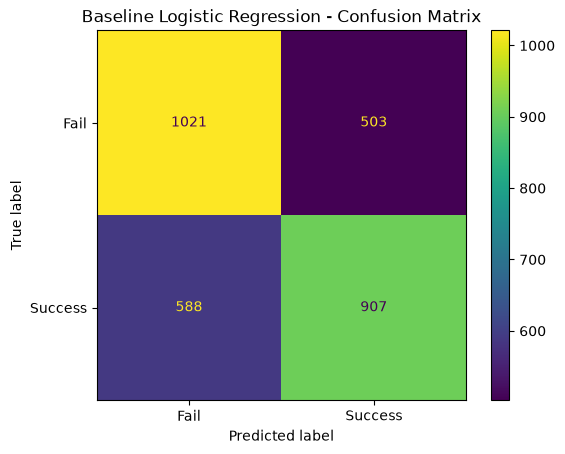

In [39]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Fail", "Success"]
)

disp.plot()
plt.title("Baseline Logistic Regression - Confusion Matrix")
plt.show()

In [40]:
coefficients = baseline_model.named_steps["model"].coef_[0]

feature_importance = pd.DataFrame({
    "feature": model_features,
    "coefficient": coefficients
})

feature_importance["abs_coefficient"] = (
    feature_importance["coefficient"].abs()
)

feature_importance = feature_importance.sort_values(
    "abs_coefficient",
    ascending=False
)

feature_importance

,feature,coefficient,abs_coefficient
2,recent_success_rate_5,0.573142,0.573142
4,previous_problem_success_rate,0.409720,0.409720
1,previous_success_rate,0.096503,0.096503
7,days_since_first_submission,-0.058786,0.058786
3,previous_problem_attempts,-0.037628,0.037628
6,day_of_week,0.021712,0.021712
5,hour,-0.012398,0.012398
0,previous_attempts,-0.011405,0.011405


In [41]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("Random Forest trained successfully!")

Random Forest trained successfully!


In [42]:
rf_pred = rf_model.predict(X_test)
rf_prob = rf_model.predict_proba(X_test)[:, 1]

print("Random Forest predictions generated!")

Random Forest predictions generated!


In [43]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

print("Accuracy :", accuracy_score(y_test, rf_pred))
print("Precision:", precision_score(y_test, rf_pred))
print("Recall   :", recall_score(y_test, rf_pred))
print("F1 Score :", f1_score(y_test, rf_pred))
print("ROC-AUC  :", roc_auc_score(y_test, rf_prob))

print("\nClassification Report:")
print(classification_report(y_test, rf_pred))

Accuracy : 0.6475654190129182
Precision: 0.6308439587128112
Recall   : 0.6949832775919732
F1 Score : 0.6613621896880968
ROC-AUC  : 0.6951287757090565

Classification Report:
              precision    recall  f1-score   support

           0       0.67      0.60      0.63      1524
           1       0.63      0.69      0.66      1495

    accuracy                           0.65      3019
   macro avg       0.65      0.65      0.65      3019
weighted avg       0.65      0.65      0.65      3019



In [44]:
rf_importance = pd.DataFrame({
    "feature": model_features,
    "importance": rf_model.feature_importances_
})

rf_importance = rf_importance.sort_values(
    "importance",
    ascending=False
)

rf_importance

,feature,importance
2,recent_success_rate_5,0.257873
4,previous_problem_success_rate,0.212350
1,previous_success_rate,0.141656
7,days_since_first_submission,0.111704
3,previous_problem_attempts,0.102616
0,previous_attempts,0.089255
5,hour,0.049430
6,day_of_week,0.035115


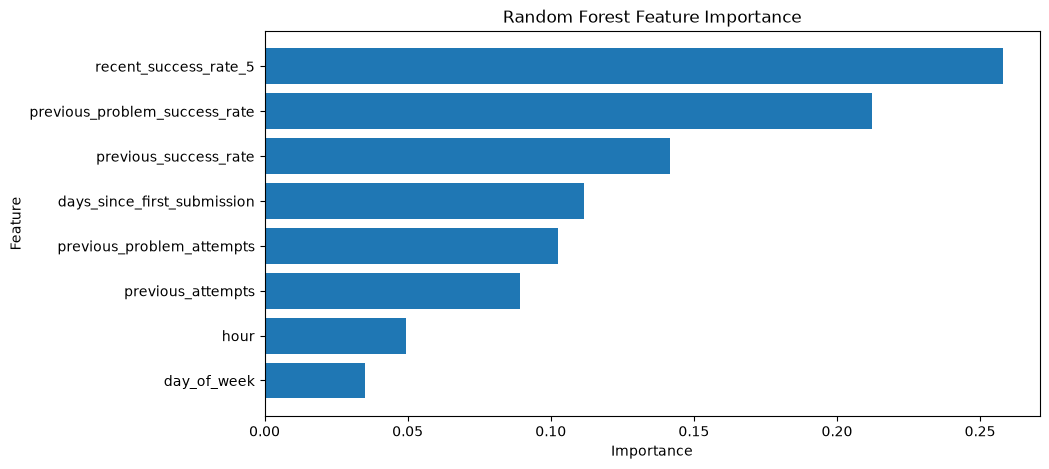

In [45]:
plt.figure(figsize=(10, 5))

plt.barh(
    rf_importance["feature"],
    rf_importance["importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importance")
plt.gca().invert_yaxis()

plt.show()

In [46]:
# Convert hour and day-of-week into cyclical features

ml_data["hour_sin"] = np.sin(
    2 * np.pi * ml_data["hour"] / 24
)

ml_data["hour_cos"] = np.cos(
    2 * np.pi * ml_data["hour"] / 24
)

ml_data["day_sin"] = np.sin(
    2 * np.pi * ml_data["day_of_week"] / 7
)

ml_data["day_cos"] = np.cos(
    2 * np.pi * ml_data["day_of_week"] / 7
)

print(
    ml_data[
        ["hour", "hour_sin", "hour_cos",
         "day_of_week", "day_sin", "day_cos"]
    ].head()
)

   hour  hour_sin  hour_cos  day_of_week   day_sin  day_cos
0    14 -0.500000 -0.866025            1  0.781831  0.62349
1    14 -0.500000 -0.866025            1  0.781831  0.62349
2    14 -0.500000 -0.866025            1  0.781831  0.62349
3    15 -0.707107 -0.707107            1  0.781831  0.62349
4    15 -0.707107 -0.707107            1  0.781831  0.62349


In [47]:
model_features_v2 = [
    "previous_attempts",
    "previous_success_rate",
    "recent_success_rate_5",
    "previous_problem_attempts",
    "previous_problem_success_rate",
    "days_since_first_submission",
    "hour_sin",
    "hour_cos",
    "day_sin",
    "day_cos"
]

X_v2 = ml_data[model_features_v2].copy()
y_v2 = ml_data["target"].copy()

split_index = int(len(ml_data) * 0.8)

X_train_v2 = X_v2.iloc[:split_index].copy()
X_test_v2 = X_v2.iloc[split_index:].copy()

y_train_v2 = y_v2.iloc[:split_index].copy()
y_test_v2 = y_v2.iloc[split_index:].copy()

print("Training shape:", X_train_v2.shape)
print("Test shape:", X_test_v2.shape)

Training shape: (12074, 10)
Test shape: (3019, 10)


In [48]:
baseline_model_v2 = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000))
])

baseline_model_v2.fit(X_train_v2, y_train_v2)

print("Improved Logistic Regression trained!")

Improved Logistic Regression trained!


In [49]:
rf_model_v2 = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

rf_model_v2.fit(X_train_v2, y_train_v2)

print("Improved Random Forest trained!")

Improved Random Forest trained!


In [50]:
lr_v2_pred = baseline_model_v2.predict(X_test_v2)
lr_v2_prob = baseline_model_v2.predict_proba(X_test_v2)[:, 1]

print("Improved Logistic Regression")
print("Accuracy :", accuracy_score(y_test_v2, lr_v2_pred))
print("Precision:", precision_score(y_test_v2, lr_v2_pred))
print("Recall   :", recall_score(y_test_v2, lr_v2_pred))
print("F1 Score :", f1_score(y_test_v2, lr_v2_pred))
print("ROC-AUC  :", roc_auc_score(y_test_v2, lr_v2_prob))

Improved Logistic Regression
Accuracy : 0.637628353759523
Precision: 0.6435218324982105
Recall   : 0.6013377926421405
F1 Score : 0.6217150760719226
ROC-AUC  : 0.6914562101142039


In [51]:
rf_v2_pred = rf_model_v2.predict(X_test_v2)
rf_v2_prob = rf_model_v2.predict_proba(X_test_v2)[:, 1]

print("Improved Random Forest")
print("Accuracy :", accuracy_score(y_test_v2, rf_v2_pred))
print("Precision:", precision_score(y_test_v2, rf_v2_pred))
print("Recall   :", recall_score(y_test_v2, rf_v2_pred))
print("F1 Score :", f1_score(y_test_v2, rf_v2_pred))
print("ROC-AUC  :", roc_auc_score(y_test_v2, rf_v2_prob))

Improved Random Forest
Accuracy : 0.6449155349453461
Precision: 0.6267225883762733
Recall   : 0.6996655518394649
F1 Score : 0.661188369152971
ROC-AUC  : 0.6906690279935744


In [52]:
from sklearn.model_selection import train_test_split

# Keep the final test set untouched.
# Split only the training data into training + validation.

val_split_index = int(len(X_train) * 0.8)

X_train_inner = X_train.iloc[:val_split_index].copy()
X_val = X_train.iloc[val_split_index:].copy()

y_train_inner = y_train.iloc[:val_split_index].copy()
y_val = y_train.iloc[val_split_index:].copy()

print("Inner training:", X_train_inner.shape)
print("Validation:", X_val.shape)

print("\nInner training period:")
print(ml_data.iloc[:val_split_index]["datetime"].min())
print("to")
print(ml_data.iloc[:val_split_index]["datetime"].max())

print("\nValidation period:")
print(ml_data.iloc[val_split_index:split_index]["datetime"].min())
print("to")
print(ml_data.iloc[val_split_index:split_index]["datetime"].max())

Inner training: (9659, 8)
Validation: (2415, 8)

Inner training period:
2017-05-16 14:20:33.791000
to
2022-10-17 19:32:15.159000

Validation period:
2022-10-17 19:58:50.526000
to
2024-02-20 01:13:32.935000


In [53]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, f1_score, accuracy_score

configs = [
    {
        "n_estimators": 200,
        "max_depth": 8,
        "min_samples_leaf": 5
    },
    {
        "n_estimators": 200,
        "max_depth": 10,
        "min_samples_leaf": 5
    },
    {
        "n_estimators": 300,
        "max_depth": 12,
        "min_samples_leaf": 5
    },
    {
        "n_estimators": 300,
        "max_depth": 15,
        "min_samples_leaf": 3
    },
    {
        "n_estimators": 300,
        "max_depth": None,
        "min_samples_leaf": 5
    }
]

results = []

for config in configs:

    model = RandomForestClassifier(
        **config,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train_inner, y_train_inner)

    val_pred = model.predict(X_val)
    val_prob = model.predict_proba(X_val)[:, 1]

    results.append({
        **config,
        "accuracy": accuracy_score(y_val, val_pred),
        "f1": f1_score(y_val, val_pred),
        "roc_auc": roc_auc_score(y_val, val_prob)
    })

tuning_results = pd.DataFrame(results)

tuning_results = tuning_results.sort_values(
    "roc_auc",
    ascending=False
)

tuning_results

,n_estimators,max_depth,min_samples_leaf,accuracy,f1,roc_auc
0,200,8.0,5,0.655901,0.622444,0.699301
1,200,10.0,5,0.647205,0.623342,0.697231
2,300,12.0,5,0.633540,0.614715,0.692052
4,300,NaN,5,0.633126,0.623619,0.686416
3,300,15.0,3,0.629814,0.624370,0.685033


In [54]:
final_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=8,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

final_model.fit(X_train, y_train)

print("Final model trained successfully!")


Final model trained successfully!


In [55]:
from sklearn.ensemble import HistGradientBoostingClassifier

hgb_model = HistGradientBoostingClassifier(
    max_iter=200,
    learning_rate=0.05,
    max_leaf_nodes=15,
    min_samples_leaf=20,
    random_state=42
)

hgb_model.fit(X_train_inner, y_train_inner)

print("HistGradientBoosting trained successfully!")

HistGradientBoosting trained successfully!


In [56]:
hgb_pred = hgb_model.predict(X_val)
hgb_prob = hgb_model.predict_proba(X_val)[:, 1]

print("HistGradientBoosting")
print("Accuracy :", accuracy_score(y_val, hgb_pred))
print("Precision:", precision_score(y_val, hgb_pred))
print("Recall   :", recall_score(y_val, hgb_pred))
print("F1 Score :", f1_score(y_val, hgb_pred))
print("ROC-AUC  :", roc_auc_score(y_val, hgb_prob))

HistGradientBoosting
Accuracy : 0.6385093167701863
Precision: 0.5691927512355849
Recall   : 0.6637848222862632
F1 Score : 0.6128603104212861
ROC-AUC  : 0.6920956923347973


In [57]:
final_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=8,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

final_model.fit(X_train, y_train)

print("Final Random Forest trained successfully!")

Final Random Forest trained successfully!


In [58]:
final_pred = final_model.predict(X_test)
final_prob = final_model.predict_proba(X_test)[:, 1]

print("Final Random Forest")
print("Accuracy :", accuracy_score(y_test, final_pred))
print("Precision:", precision_score(y_test, final_pred))
print("Recall   :", recall_score(y_test, final_pred))
print("F1 Score :", f1_score(y_test, final_pred))
print("ROC-AUC  :", roc_auc_score(y_test, final_prob))

print("\nClassification Report:")
print(classification_report(
    y_test,
    final_pred,
    target_names=["Fail", "Success"]
))

Final Random Forest
Accuracy : 0.6419344153693276
Precision: 0.628731343283582
Recall   : 0.6762541806020067
F1 Score : 0.6516274572993876
ROC-AUC  : 0.696301099904318

Classification Report:
              precision    recall  f1-score   support

        Fail       0.66      0.61      0.63      1524
     Success       0.63      0.68      0.65      1495

    accuracy                           0.64      3019
   macro avg       0.64      0.64      0.64      3019
weighted avg       0.64      0.64      0.64      3019



[[ 927  597]
 [ 484 1011]]


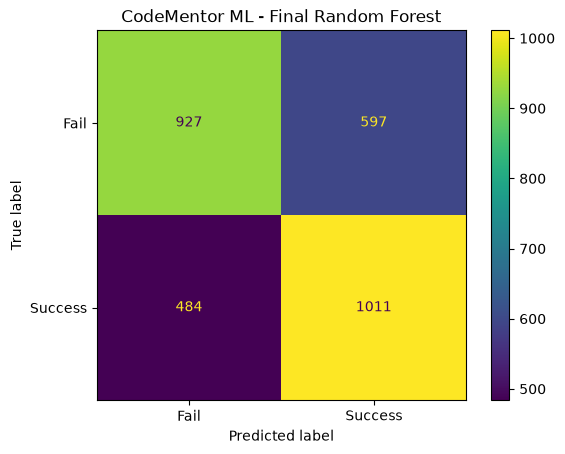

In [59]:
final_cm = confusion_matrix(y_test, final_pred)

print(final_cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=final_cm,
    display_labels=["Fail", "Success"]
)

disp.plot()
plt.title("CodeMentor ML - Final Random Forest")
plt.show()

In [60]:
print("Shape:", questions.shape)
print("\nColumns:")
print(questions.columns.tolist())

print("\nFirst 5 questions:")
display(questions.head())

print("\nMissing values:")
print(questions.isna().sum())

Shape: (99, 3)

Columns:
['question', 'statement', 'tests']

First 5 questions:


,question,statement,tests
0,bst_height,# BST Height\n\n The height of a tree is t...,['input: |\n 10 8 1 9 20 18 25\n out...
1,tree_height,# Height of a Tree\n \n Although trees s...,['input: |\n 1\n output: |\n ...
2,similar_trees,# Similar trees\n\n Two trees are said to b...,['input: |\n 3\n 2\n 1\n 3...
3,balance,# Balance in Binary Search Trees\n\n *The b...,['input: |\n 100 200 210 90 95 70 1\n ...
4,bfs,# Width Forwarding (BFS)\n\n There are seve...,['input: |\n 9\n output: |\n ...



Missing values:
question     0
statement    0
tests        0
dtype: int64


In [61]:
print("Unique questions:", questions["question"].nunique())

print("\nExample question names:")
print(questions["question"].head(20).tolist())

Unique questions: 99

Example question names:
['bst_height', 'tree_height', 'similar_trees', 'balance', 'bfs', 'right_bfs', 'bubble_sort_step_by_step', 'build_heap', 'binary_search', 'recursive_binary_search', 'bst_search', 'recursive_linear_search', 'check_tree', 'count_leaves', 'count_internal_nodes_bst', 'negative_counting_sort', 'counting_sort_step_by_step', 'two_add_up', 'down_n', 'element_at_stack']


In [62]:
for i, q in enumerate(questions["question"], start=1):
    print(f"{i:02d}. {q}")

01. bst_height
02. tree_height
03. similar_trees
04. balance
05. bfs
06. right_bfs
07. bubble_sort_step_by_step
08. build_heap
09. binary_search
10. recursive_binary_search
11. bst_search
12. recursive_linear_search
13. check_tree
14. count_leaves
15. count_internal_nodes_bst
16. negative_counting_sort
17. counting_sort_step_by_step
18. two_add_up
19. down_n
20. element_at_stack
21. leftover_element
22. duplicate_elements
23. routing_bst
24. find_element
25. find_first_negative
26. recursive_break_finder
27. equals_bst
28. order_statistic
29. mathematical_expression
30. fibonacci
31. queue_with_array
32. filter_linked_list
33. frequency_element
34. queue_jumper
35. hashset
36. sorted_insertion_first
37. sorted_insertion_last
38. recursive_insertion_sort
39. invert_array
40. invert_phrase
41. invert_stack
42. invert_stack_index
43. invert_stack_without_queue
44. is_heap
45. linked_list
46. adjacency_list
47. mariana_and_books
48. adjacency_matrix
49. max_bst
50. max_stack
51. max_stack_

In [63]:
topic_rules = {
    "Trees / BST": [
        "bst", "tree", "predecessor", "successor",
        "order_statistic", "routing_bst",
        "equals_bst", "removal_bst", "rotations_bst",
        "nearest_value_bst"
    ],

    "Graphs": [
        "bfs", "adjacency"
    ],

    "Sorting": [
        "sort", "sorting", "counting_sort",
        "radix_sort", "heap"
    ],

    "Searching": [
        "binary_search", "linear_search",
        "find_element", "find_first_negative",
        "element_positions"
    ],

    "Stack": [
        "stack", "brackets", "reverse_polish"
    ],

    "Queue": [
        "queue"
    ],

    "Linked List": [
        "linked_list", "linkedlist"
    ],

    "Hashing": [
        "hash"
    ],

    "Recursion": [
        "recursive", "fibonacci",
        "power", "tower_of_hanoi",
        "three_n_plus_one"
    ],

    "Arrays": [
        "array", "invert_array",
        "swap_neighbors", "circular_vector"
    ],

    "Partitioning": [
        "partition", "pivot"
    ],

    "Heap": [
        "heap"
    ],

    "String / Text": [
        "phrase", "stopwords",
        "word_cloud"
    ],

    "Math / Theory": [
        "master_theorem",
        "mathematical_expression"
    ]
}

In [64]:
def assign_topic(question_name):
    name = question_name.lower()

    for topic, keywords in topic_rules.items():
        for keyword in keywords:
            if keyword in name:
                return topic

    return "Miscellaneous"



In [65]:
questions["topic"] = questions["question"].apply(assign_topic)

In [66]:
display(
    questions[["question", "topic"]]
    .sort_values("topic")
    .reset_index(drop=True)
)

,question,topic
0,circular_vector,Arrays
1,swap_neighbors,Arrays
2,invert_array,Arrays
3,bfs,Graphs
4,right_bfs,Graphs
...,...,...
94,predecessor_bst,Trees / BST
95,number_larger_elements_bst,Trees / BST
96,number_smaller_elements_bst,Trees / BST
97,rotations_bst,Trees / BST


In [67]:
print(questions["topic"].value_counts())

topic
Trees / BST      18
Sorting          18
Miscellaneous    16
Stack             9
Searching         6
Recursion         5
Linked List       5
Partitioning      5
Graphs            4
Hashing           3
Arrays            3
String / Text     3
Math / Theory     2
Queue             2
Name: count, dtype: int64


In [68]:
topic_rules = {
    "Trees / BST": [
        "bst", "tree", "predecessor", "successor",
        "order_statistic", "routing_bst",
        "equals_bst", "removal_bst", "rotations_bst",
        "nearest_value_bst"
    ],

    "Graphs": [
        "bfs", "adjacency"
    ],

    "Sorting": [
        "bubble_sort", "counting_sort",
        "merge_sort", "quick_sort",
        "selection_sort", "insertion_sort",
        "radix_sort", "stooge_sort"
    ],

    "Searching": [
        "binary_search", "linear_search",
        "find_element", "find_first_negative",
        "element_positions"
    ],

    "Stack": [
        "stack", "brackets", "reverse_polish"
    ],

    "Queue": [
        "queue"
    ],

    "Linked List": [
        "linked_list", "linkedlist"
    ],

    "Hashing": [
        "hashset", "hash_table"
    ],

    "Recursion": [
        "recursive", "fibonacci",
        "power", "tower_of_hanoi",
        "three_n_plus_one"
    ],

    "Arrays": [
        "array", "invert_array",
        "swap_neighbors", "circular_vector"
    ],

    "Partitioning": [
        "partition", "pivot"
    ],

    "Heap": [
        "heap"
    ],

    "String / Text": [
        "phrase", "stopwords",
        "word_cloud"
    ],

    "Math / Theory": [
        "master_theorem",
        "mathematical_expression"
    ]
}

In [69]:
questions["topic"] = questions["question"].apply(assign_topic)

display(
    questions[["question", "topic"]]
    .sort_values("topic")
    .reset_index(drop=True)
)

,question,topic
0,circular_vector,Arrays
1,invert_array,Arrays
2,swap_neighbors,Arrays
3,adjacency_matrix,Graphs
4,bfs,Graphs
...,...,...
94,predecessor_bst,Trees / BST
95,number_larger_elements_bst,Trees / BST
96,number_smaller_elements_bst,Trees / BST
97,rotations_bst,Trees / BST


In [70]:
print(questions["topic"].value_counts())

topic
Miscellaneous    19
Trees / BST      18
Sorting          12
Stack            10
Searching         6
Recursion         5
Linked List       5
Partitioning      5
Graphs            4
Hashing           3
Arrays            3
String / Text     3
Heap              2
Math / Theory     2
Queue             2
Name: count, dtype: int64


In [71]:
misc_questions = questions[
    questions["topic"] == "Miscellaneous"
]

print(misc_questions["question"].tolist())

['balance', 'count_leaves', 'two_add_up', 'down_n', 'leftover_element', 'duplicate_elements', 'frequency_element', 'sorted_insertion_first', 'sorted_insertion_last', 'mariana_and_books', 'move_impostor', 'move_n', 'move_three', 'plates_sorting', 'without_pair', 'sum_leaves', 'frequency_table', 'top_n', 'warm_up_dsa']


In [72]:
topic_rules["Trees / BST"].extend([
    "balance",
    "count_leaves",
    "count_internal_nodes",
    "sum_leaves"
])

topic_rules["Arrays"].extend([
    "two_add_up",
    "duplicate_elements",
    "without_pair"
])

topic_rules["Hashing"].extend([
    "frequency_element",
    "frequency_table"
])

topic_rules["Linked List"].extend([
    "sorted_insertion"
])

topic_rules["Heap"].extend([
    "top_n"
])

In [73]:
questions["topic"] = questions["question"].apply(assign_topic)

print(questions["topic"].value_counts())

topic
Trees / BST      21
Sorting          12
Stack            10
Miscellaneous     8
Linked List       7
Searching         6
Arrays            6
Recursion         5
Hashing           5
Partitioning      5
Graphs            4
Heap              3
String / Text     3
Math / Theory     2
Queue             2
Name: count, dtype: int64


In [74]:
print(
    questions.loc[
        questions["topic"] == "Miscellaneous",
        "question"
    ].tolist()
)

['down_n', 'leftover_element', 'mariana_and_books', 'move_impostor', 'move_n', 'move_three', 'plates_sorting', 'warm_up_dsa']


In [75]:
question_topics = questions[
    ["question", "topic"]
].copy()

ml_data = ml_data.merge(
    question_topics,
    left_on="activity",
    right_on="question",
    how="left"
)

In [76]:
print("Total submissions:", len(ml_data))
print("Missing topics:", ml_data["topic"].isna().sum())

Total submissions: 15093
Missing topics: 0


In [77]:
display(
    ml_data[
        ["user", "activity", "topic", "target"]
    ].head(20)
)

,user,activity,topic,target
0,user_0001,duplicate_elements,Arrays,0
1,user_0001,duplicate_elements,Arrays,0
2,user_0001,recursive_power,Recursion,0
3,user_0001,duplicate_elements,Arrays,0
4,user_0001,duplicate_elements,Arrays,0
5,user_0001,master_theorem,Math / Theory,1
6,user_0001,master_theorem,Math / Theory,1
7,user_0005,master_theorem,Math / Theory,1
8,user_0005,master_theorem,Math / Theory,1
9,user_0005,master_theorem,Math / Theory,1


In [78]:
topic_performance = (
    ml_data
    .groupby(["user", "topic"])
    .agg(
        attempts=("target", "count"),
        successes=("target", "sum"),
        success_rate=("target", "mean")
    )
    .reset_index()
)

topic_performance["success_rate"] *= 100

display(topic_performance.head(20))

,user,topic,attempts,successes,success_rate
0,user_0001,Arrays,4,0,0.000000
1,user_0001,Graphs,1,1,100.000000
2,user_0001,Hashing,5,0,0.000000
3,user_0001,Heap,4,2,50.000000
4,user_0001,Linked List,14,2,14.285714
5,user_0001,Math / Theory,2,2,100.000000
6,user_0001,Partitioning,3,1,33.333333
7,user_0001,Queue,1,1,100.000000
8,user_0001,Recursion,1,0,0.000000
9,user_0001,Sorting,2,2,100.000000


In [79]:
MIN_ATTEMPTS = 3

weak_topics = topic_performance[
    topic_performance["attempts"] >= MIN_ATTEMPTS
].copy()

weak_topics = weak_topics.sort_values(
    ["user", "success_rate", "attempts"],
    ascending=[True, True, False]
)

display(weak_topics.head(30))

,user,topic,attempts,successes,success_rate
2,user_0001,Hashing,5,0,0.000000
0,user_0001,Arrays,4,0,0.000000
4,user_0001,Linked List,14,2,14.285714
6,user_0001,Partitioning,3,1,33.333333
3,user_0001,Heap,4,2,50.000000
10,user_0001,Stack,4,3,75.000000
12,user_0001,Trees / BST,9,8,88.888889
20,user_0002,Queue,10,1,10.000000
15,user_0002,Hashing,11,2,18.181818
19,user_0002,Partitioning,8,2,25.000000


In [80]:
display(
    weak_topics[
        weak_topics["user"] == "user_0001"
    ]
)

,user,topic,attempts,successes,success_rate
2,user_0001,Hashing,5,0,0.000000
0,user_0001,Arrays,4,0,0.000000
4,user_0001,Linked List,14,2,14.285714
6,user_0001,Partitioning,3,1,33.333333
3,user_0001,Heap,4,2,50.000000
10,user_0001,Stack,4,3,75.000000
12,user_0001,Trees / BST,9,8,88.888889


In [81]:
import numpy as np

weak_topics["success_rate_fraction"] = (
    weak_topics["success_rate"] / 100
)

weak_topics["weakness_score"] = (
    (1 - weak_topics["success_rate_fraction"])
    * np.log1p(weak_topics["attempts"])
)

In [82]:
display(
    weak_topics[
        weak_topics["user"] == "user_0001"
    ][
        [
            "topic",
            "attempts",
            "successes",
            "success_rate",
            "weakness_score"
        ]
    ].sort_values(
        "weakness_score",
        ascending=False
    )
)

,topic,attempts,successes,success_rate,weakness_score
4,Linked List,14,2,14.285714,2.321186
2,Hashing,5,0,0.000000,1.791759
0,Arrays,4,0,0.000000,1.609438
6,Partitioning,3,1,33.333333,0.924196
3,Heap,4,2,50.000000,0.804719
10,Stack,4,3,75.000000,0.402359
12,Trees / BST,9,8,88.888889,0.255843


In [83]:
top_weak_topics = (
    weak_topics
    .sort_values(
        ["user", "weakness_score"],
        ascending=[True, False]
    )
    .groupby("user")
    .head(3)
)

display(top_weak_topics.head(30))

,user,topic,attempts,successes,success_rate,success_rate_fraction,weakness_score
4,user_0001,Linked List,14,2,14.285714,0.142857,2.321186
2,user_0001,Hashing,5,0,0.000000,0.000000,1.791759
0,user_0001,Arrays,4,0,0.000000,0.000000,1.609438
20,user_0002,Queue,10,1,10.000000,0.100000,2.158106
15,user_0002,Hashing,11,2,18.181818,0.181818,2.033105
19,user_0002,Partitioning,8,2,25.000000,0.250000,1.647918
27,user_0003,Hashing,5,1,20.000000,0.200000,1.433408
33,user_0003,Queue,6,2,33.333333,0.333333,1.297273
32,user_0003,Partitioning,7,3,42.857143,0.428571,1.188252
41,user_0004,Hashing,51,1,1.960784,0.019608,3.873768


In [84]:
weak_topic_counts = (
    top_weak_topics["topic"]
    .value_counts()
    .reset_index()
)

weak_topic_counts.columns = [
    "topic",
    "students"
]

display(weak_topic_counts)

,topic,students
0,Linked List,89
1,Sorting,86
2,Arrays,83
3,Miscellaneous,70
4,Trees / BST,58
5,Queue,56
6,Stack,44
7,Searching,43
8,Hashing,42
9,Partitioning,34


In [85]:
weak_topic_counts = (
    top_weak_topics["topic"]
    .value_counts()
    .reset_index()
)

weak_topic_counts.columns = [
    "topic",
    "students"
]

display(weak_topic_counts)

,topic,students
0,Linked List,89
1,Sorting,86
2,Arrays,83
3,Miscellaneous,70
4,Trees / BST,58
5,Queue,56
6,Stack,44
7,Searching,43
8,Hashing,42
9,Partitioning,34


In [86]:
misc_questions = questions[
    questions["topic"] == "Miscellaneous"
][["question", "topic"]]

display(misc_questions)

,question,topic
18,down_n,Miscellaneous
20,leftover_element,Miscellaneous
46,mariana_and_books,Miscellaneous
54,move_impostor,Miscellaneous
55,move_n,Miscellaneous
56,move_three,Miscellaneous
58,plates_sorting,Miscellaneous
97,warm_up_dsa,Miscellaneous


In [87]:
misc_details = questions[
    questions["topic"] == "Miscellaneous"
][["question", "statement"]]

for _, row in misc_details.iterrows():
    print("=" * 80)
    print("QUESTION:", row["question"])
    print(row["statement"])
    print()

QUESTION: down_n
# Down-n
    
    Write a program that prints the 
    **n** smallest elements of a sequence.

    ## Input

    Your program should read two lines of standard input. The first
    is a sequence of space-separated integers and the 
    second an integer **n** representing the number of elements to be printed.
    

    Important: you can consider that n is always greater than or equal to 1 and less than or
    equal to the number of elements in the sequence.

    ## Output

    Your program should print the n smallest elements of the sequence read in ascending order.

    ## Example
    
        javac Solution.java; java Solution
        9 3 1 7 34 22 101 7 300 1 45
        3
        1 1 3

        javac Solution.java; java Solution
        9 3 1 7 34 22 101 7 300 1 45
        4
        1 1 3 7

    ## Tip

    Use Arrays.toString().
    
    ## Restrictions
    
    You may not use auxiliary arrays.

    You may not use Arrays.sort or any ready-made
    method from so

In [88]:
topic_rules["Sorting"].extend([
    "down_n",
    "mariana_and_books",
    "move_impostor",
    "move_n",
    "move_three",
    "plates_sorting"
])

topic_rules["Arrays"].extend([
    "leftover_element",
    "warm_up_dsa"
])

In [89]:
questions["topic"] = questions["question"].apply(assign_topic)

display(
    questions[["question", "topic"]]
)

,question,topic
0,bst_height,Trees / BST
1,tree_height,Trees / BST
2,similar_trees,Trees / BST
3,balance,Trees / BST
4,bfs,Graphs
...,...,...
94,swap_neighbors_linked_list,Linked List
95,nearest_value_bst,Trees / BST
96,circular_vector,Arrays
97,warm_up_dsa,Arrays


In [90]:
question_topics = questions[["question", "topic"]].copy()

ml_data = ml_data.drop(columns=["topic", "question"], errors="ignore")

ml_data = ml_data.merge(
    question_topics,
    left_on="activity",
    right_on="question",
    how="left"
)

In [91]:
print("Missing topics:", ml_data["topic"].isna().sum())
print("Miscellaneous submissions:", (ml_data["topic"] == "Miscellaneous").sum())

Missing topics: 0
Miscellaneous submissions: 0


In [92]:
topic_performance = (
    ml_data
    .groupby(["user", "topic"])
    .agg(
        attempts=("target", "count"),
        successes=("target", "sum"),
        success_rate=("target", "mean")
    )
    .reset_index()
)

topic_performance["success_rate"] *= 100

In [93]:
MIN_ATTEMPTS = 3

weak_topics = topic_performance[
    topic_performance["attempts"] >= MIN_ATTEMPTS
].copy()

weak_topics["success_rate_fraction"] = (
    weak_topics["success_rate"] / 100
)

weak_topics["weakness_score"] = (
    (1 - weak_topics["success_rate_fraction"])
    * np.log1p(weak_topics["attempts"])
)


In [94]:
top_weak_topics = (
    weak_topics
    .sort_values(
        ["user", "weakness_score"],
        ascending=[True, False]
    )
    .groupby("user")
    .head(3)
)

display(top_weak_topics.head(20))

,user,topic,attempts,successes,success_rate,success_rate_fraction,weakness_score
4,user_0001,Linked List,14,2,14.285714,0.142857,2.321186
2,user_0001,Hashing,5,0,0.000000,0.000000,1.791759
0,user_0001,Arrays,4,0,0.000000,0.000000,1.609438
20,user_0002,Queue,10,1,10.000000,0.100000,2.158106
15,user_0002,Hashing,11,2,18.181818,0.181818,2.033105
19,user_0002,Partitioning,8,2,25.000000,0.250000,1.647918
27,user_0003,Hashing,5,1,20.000000,0.200000,1.433408
32,user_0003,Queue,6,2,33.333333,0.333333,1.297273
31,user_0003,Partitioning,7,3,42.857143,0.428571,1.188252
40,user_0004,Hashing,51,1,1.960784,0.019608,3.873768


In [95]:
weak_topic_counts = (
    top_weak_topics["topic"]
    .value_counts()
    .reset_index()
)

weak_topic_counts.columns = [
    "topic",
    "students"
]

display(weak_topic_counts)

,topic,students
0,Sorting,117
1,Arrays,110
2,Linked List,91
3,Trees / BST,60
4,Queue,56
5,Stack,45
6,Searching,44
7,Hashing,43
8,Partitioning,34
9,String / Text,24


In [96]:
problem_topic_counts = (
    questions["topic"]
    .value_counts()
    .reset_index()
)

problem_topic_counts.columns = [
    "topic",
    "problems"
]

display(problem_topic_counts)

,topic,problems
0,Trees / BST,21
1,Sorting,18
2,Stack,10
3,Arrays,8
4,Linked List,7
5,Searching,6
6,Recursion,5
7,Hashing,5
8,Partitioning,5
9,Graphs,4


In [97]:
student_problem_history = (
    ml_data
    .groupby(["user", "activity"])
    .agg(
        attempts=("target", "count"),
        successes=("target", "sum"),
        success_rate=("target", "mean")
    )
    .reset_index()
)

student_problem_history["success_rate"] *= 100

display(student_problem_history.head(20))

,user,activity,attempts,successes,success_rate
0,user_0001,bfs,1,1,100.000000
1,user_0001,brackets,3,2,66.666667
2,user_0001,bst_height,1,1,100.000000
3,user_0001,bst_search,1,1,100.000000
4,user_0001,build_heap,3,1,33.333333
5,user_0001,duplicate_elements,4,0,0.000000
6,user_0001,hash_table_chaining,3,0,0.000000
7,user_0001,hash_table_probing,2,0,0.000000
8,user_0001,invert_phrase,1,1,100.000000
9,user_0001,is_heap,1,1,100.000000


In [98]:
solved_problems = student_problem_history[
    student_problem_history["successes"] > 0
][["user", "activity"]].copy()

solved_problems["solved"] = True

display(solved_problems.head(20))

,user,activity,solved
0,user_0001,bfs,True
1,user_0001,brackets,True
2,user_0001,bst_height,True
3,user_0001,bst_search,True
4,user_0001,build_heap,True
8,user_0001,invert_phrase,True
9,user_0001,is_heap,True
10,user_0001,master_theorem,True
11,user_0001,merge_sort_step_by_step,True
12,user_0001,nearest_value_bst,True


In [99]:
user_id = "user_0001"

user_weak_topics = (
    top_weak_topics[
        top_weak_topics["user"] == user_id
    ][["topic", "weakness_score"]]
)

display(user_weak_topics)

,topic,weakness_score
4,Linked List,2.321186
2,Hashing,1.791759
0,Arrays,1.609438


In [100]:
user_solved = set(
    solved_problems[
        solved_problems["user"] == user_id
    ]["activity"]
)

print("Solved problems:", len(user_solved))
print(user_solved)

Solved problems: 19
{'build_heap', 'stack_with_array', 'negative_counting_sort', 'merge_sort_step_by_step', 'sorted_insertion_last', 'nearest_value_bst', 'bst_search', 'invert_phrase', 'stable_partition', 'brackets', 'is_heap', 'order_statistic', 'bfs', 'bst_height', 'routing_bst', 'queue_with_array', 'sorted_insertion_first', 'master_theorem', 'number_smaller_elements_bst'}


In [101]:
candidate_problems = questions[
    questions["topic"].isin(user_weak_topics["topic"])
].copy()

candidate_problems = candidate_problems[
    ~candidate_problems["question"].isin(user_solved)
].copy()

display(
    candidate_problems[
        ["question", "topic"]
    ]
)

,question,topic
17,two_add_up,Arrays
20,leftover_element,Arrays
21,duplicate_elements,Arrays
31,filter_linked_list,Linked List
32,frequency_element,Hashing
34,hashset,Hashing
38,invert_array,Arrays
44,linked_list,Linked List
76,remove_index_linkedlist,Linked List
80,without_pair,Arrays


In [102]:
problem_difficulty = (
    ml_data
    .groupby("activity")
    .agg(
        total_attempts=("target", "count"),
        total_successes=("target", "sum"),
        success_rate=("target", "mean")
    )
    .reset_index()
)

problem_difficulty["success_rate"] *= 100

display(
    problem_difficulty.sort_values(
        "success_rate"
    ).head(20)
)

,activity,total_attempts,total_successes,success_rate
59,queue_with_array,899,120,13.348165
1,adjacency_matrix,20,3,15.000000
28,hash_table_probing,273,44,16.117216
11,check_tree,103,17,16.504854
27,hash_table_chaining,193,38,19.689119
9,bubble_sort_step_by_step,159,34,21.383648
51,nearest_value_bst,206,51,24.757282
76,similar_trees,19,5,26.315789
75,selection_sort_step_by_step,484,130,26.859504
42,mathematical_expression,26,7,26.923077


In [103]:
user_attempts = (
    student_problem_history[
        student_problem_history["user"] == user_id
    ][["activity", "attempts"]]
    .rename(columns={"attempts": "user_attempts"})
)

candidate_problems = candidate_problems.merge(
    user_attempts,
    left_on="question",
    right_on="activity",
    how="left"
)

candidate_problems["user_attempts"] = (
    candidate_problems["user_attempts"].fillna(0)
)

display(candidate_problems)

,question,statement,tests,topic,activity,user_attempts
0,two_add_up,# Two add up\n \n Write a program that r...,['input: |\n 1 3 2 5\n 6\n ou...,Arrays,NaN,0.0
1,leftover_element,# Leftover element\n\n Consider two arrays ...,['input: |\n 1 2 3 4 5\n 1 2 3 4...,Arrays,NaN,0.0
2,duplicate_elements,# Checking for duplicate elements\n\n Write...,['input: |\n 1 5 6 8 8 4 2 0\n outpu...,Arrays,duplicate_elements,4.0
3,filter_linked_list,# Filter LinkedList\n\n Write a program tha...,['input: |\n 1 13 3 4 5 3 6\n 3\...,Linked List,NaN,0.0
4,frequency_element,# Frequency of an element in a sequence\n \...,['input: |\n 7\n 1 5 3 2 88 9 2\...,Hashing,NaN,0.0
5,hashset,# HashSet\n\n HashSets implement the mathem...,['input: |\n 5\n put 0\n ...,Hashing,NaN,0.0
6,invert_array,# Invert Array\n\n Implement a program that...,['input: |\n 1 2 4\n output: |\n ...,Arrays,NaN,0.0
7,linked_list,# Queue (Linked List)\n\n Implement a queue...,['input: |\n print\n add 2\n ...,Linked List,NaN,0.0
8,remove_index_linkedlist,# Remove Index LinkedList\n\n Write a progr...,['input: |\n 1 13 3 4 5\n 1\n ...,Linked List,NaN,0.0
9,without_pair,# Without pair\n \n Write a program that...,['input: |\n 1 2 3 2 1\n type: io\n ...,Arrays,NaN,0.0


In [104]:
candidate_problems = candidate_problems.merge(
    problem_difficulty[
        ["activity", "success_rate"]
    ].rename(
        columns={
            "activity": "question",
            "success_rate": "problem_success_rate"
        }
    ),
    on="question",
    how="left"
)

display(
    candidate_problems[
        [
            "question",
            "topic",
            "user_attempts",
            "problem_success_rate"
        ]
    ]
)

,question,topic,user_attempts,problem_success_rate
0,two_add_up,Arrays,0.0,48.695652
1,leftover_element,Arrays,0.0,58.823529
2,duplicate_elements,Arrays,4.0,44.165621
3,filter_linked_list,Linked List,0.0,56.451613
4,frequency_element,Hashing,0.0,51.824818
5,hashset,Hashing,0.0,31.428571
6,invert_array,Arrays,0.0,83.333333
7,linked_list,Linked List,0.0,27.446301
8,remove_index_linkedlist,Linked List,0.0,45.871560
9,without_pair,Arrays,0.0,65.217391


In [105]:
# Add weakness score for each candidate's topic
candidate_problems = candidate_problems.merge(
    user_weak_topics,
    on="topic",
    how="left"
)

# Normalize the challenge signal
candidate_problems["challenge_score"] = (
    1 - candidate_problems["problem_success_rate"] / 100
)

# New-problem bonus
candidate_problems["new_problem_bonus"] = (
    candidate_problems["user_attempts"] == 0
).astype(int)

# Final recommendation score
candidate_problems["recommendation_score"] = (
    0.60 * candidate_problems["weakness_score"]
    + 0.25 * candidate_problems["new_problem_bonus"]
    + 0.15 * candidate_problems["challenge_score"]
)

# Rank recommendations
recommendations = (
    candidate_problems
    .sort_values(
        "recommendation_score",
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    recommendations[
        [
            "question",
            "topic",
            "user_attempts",
            "problem_success_rate",
            "weakness_score",
            "new_problem_bonus",
            "challenge_score",
            "recommendation_score"
        ]
    ]
)

,question,topic,user_attempts,problem_success_rate,weakness_score,new_problem_bonus,challenge_score,recommendation_score
0,linked_list,Linked List,0.0,27.446301,2.321186,1,0.725537,1.751542
1,trim_linked_list,Linked List,0.0,32.530120,2.321186,1,0.674699,1.743916
2,swap_neighbors_linked_list,Linked List,0.0,39.694656,2.321186,1,0.603053,1.733170
3,remove_index_linkedlist,Linked List,0.0,45.871560,2.321186,1,0.541284,1.723904
4,filter_linked_list,Linked List,0.0,56.451613,2.321186,1,0.435484,1.708034
5,hashset,Hashing,0.0,31.428571,1.791759,1,0.685714,1.427913
6,frequency_table,Hashing,0.0,32.584270,1.791759,1,0.674157,1.426179
7,frequency_element,Hashing,0.0,51.824818,1.791759,1,0.481752,1.397318
8,circular_vector,Arrays,0.0,42.711864,1.609438,1,0.572881,1.301595
9,warm_up_dsa,Arrays,0.0,44.652406,1.609438,1,0.553476,1.298684


In [106]:
# Normalize weakness score between 0 and 1
max_weakness = candidate_problems["weakness_score"].max()

candidate_problems["weakness_score_norm"] = (
    candidate_problems["weakness_score"] / max_weakness
)

# Recalculate recommendation score
candidate_problems["recommendation_score"] = (
    0.60 * candidate_problems["weakness_score_norm"]
    + 0.25 * candidate_problems["new_problem_bonus"]
    + 0.15 * candidate_problems["challenge_score"]
)

# Final ranking
recommendations = (
    candidate_problems
    .sort_values(
        "recommendation_score",
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    recommendations[
        [
            "question",
            "topic",
            "user_attempts",
            "problem_success_rate",
            "weakness_score_norm",
            "new_problem_bonus",
            "challenge_score",
            "recommendation_score"
        ]
    ].head(10)
)

,question,topic,user_attempts,problem_success_rate,weakness_score_norm,new_problem_bonus,challenge_score,recommendation_score
0,linked_list,Linked List,0.0,27.446301,1.000000,1,0.725537,0.958831
1,trim_linked_list,Linked List,0.0,32.530120,1.000000,1,0.674699,0.951205
2,swap_neighbors_linked_list,Linked List,0.0,39.694656,1.000000,1,0.603053,0.940458
3,remove_index_linkedlist,Linked List,0.0,45.871560,1.000000,1,0.541284,0.931193
4,filter_linked_list,Linked List,0.0,56.451613,1.000000,1,0.435484,0.915323
5,hashset,Hashing,0.0,31.428571,0.771916,1,0.685714,0.816006
6,frequency_table,Hashing,0.0,32.584270,0.771916,1,0.674157,0.814273
7,frequency_element,Hashing,0.0,51.824818,0.771916,1,0.481752,0.785412
8,circular_vector,Arrays,0.0,42.711864,0.693369,1,0.572881,0.751953
9,warm_up_dsa,Arrays,0.0,44.652406,0.693369,1,0.553476,0.749043


In [107]:
def recommend_problems(user_id, top_n=5):
    
    # Get this user's weak topics
    user_weak_topics = (
        top_weak_topics[
            top_weak_topics["user"] == user_id
        ][["topic", "weakness_score"]]
        .copy()
    )
    
    # If no weak topics exist
    if user_weak_topics.empty:
        return pd.DataFrame()
    
    # Get problems already solved by the user
    user_solved = set(
        solved_problems[
            solved_problems["user"] == user_id
        ]["activity"]
    )
    
    # Candidate problems from weak topics
    candidates = questions[
        questions["topic"].isin(
            user_weak_topics["topic"]
        )
    ].copy()
    
    # Remove already solved problems
    candidates = candidates[
        ~candidates["question"].isin(user_solved)
    ].copy()
    
    # Add user's previous attempts
    user_attempts = (
        student_problem_history[
            student_problem_history["user"] == user_id
        ][["activity", "attempts"]]
        .rename(
            columns={"attempts": "user_attempts"}
        )
    )
    
    candidates = candidates.merge(
        user_attempts,
        left_on="question",
        right_on="activity",
        how="left"
    )
    
    candidates["user_attempts"] = (
        candidates["user_attempts"]
        .fillna(0)
    )
    
    # Add historical problem success rate
    candidates = candidates.merge(
        problem_difficulty[
            ["activity", "success_rate"]
        ].rename(
            columns={
                "activity": "question",
                "success_rate":
                    "problem_success_rate"
            }
        ),
        on="question",
        how="left"
    )
    
    # Add topic weakness
    candidates = candidates.merge(
        user_weak_topics,
        on="topic",
        how="left"
    )
    
    # Normalize weakness
    max_weakness = (
        candidates["weakness_score"].max()
    )
    
    if max_weakness > 0:
        candidates["weakness_score_norm"] = (
            candidates["weakness_score"]
            / max_weakness
        )
    else:
        candidates["weakness_score_norm"] = 0
    
    # Challenge signal
    candidates["challenge_score"] = (
        1 -
        candidates["problem_success_rate"] / 100
    )
    
    # New problem bonus
    candidates["new_problem_bonus"] = (
        candidates["user_attempts"] == 0
    ).astype(int)
    
    # Final recommendation score
    candidates["recommendation_score"] = (
        0.60 *
        candidates["weakness_score_norm"]
        +
        0.25 *
        candidates["new_problem_bonus"]
        +
        0.15 *
        candidates["challenge_score"]
    )
    
    # Sort and return top recommendations
    recommendations = (
        candidates
        .sort_values(
            "recommendation_score",
            ascending=False
        )
        .head(top_n)
        .reset_index(drop=True)
    )
    
    return recommendations[
        [
            "question",
            "topic",
            "user_attempts",
            "problem_success_rate",
            "recommendation_score"
        ]
    ]

In [108]:
recommendations = recommend_problems(
    "user_0001",
    top_n=5
)

display(recommendations)

,question,topic,user_attempts,problem_success_rate,recommendation_score
0,linked_list,Linked List,0.0,27.446301,0.958831
1,trim_linked_list,Linked List,0.0,32.530120,0.951205
2,swap_neighbors_linked_list,Linked List,0.0,39.694656,0.940458
3,remove_index_linkedlist,Linked List,0.0,45.871560,0.931193
4,filter_linked_list,Linked List,0.0,56.451613,0.915323


In [109]:
test_users = [
    "user_0001",
    "user_0002",
    "user_0003",
    "user_0029",
    "user_0224"
]

for uid in test_users:
    print(f"\n===== {uid} =====")
    
    recs = recommend_problems(
        uid,
        top_n=5
    )
    
    display(recs)


===== user_0001 =====


,question,topic,user_attempts,problem_success_rate,recommendation_score
0,linked_list,Linked List,0.0,27.446301,0.958831
1,trim_linked_list,Linked List,0.0,32.530120,0.951205
2,swap_neighbors_linked_list,Linked List,0.0,39.694656,0.940458
3,remove_index_linkedlist,Linked List,0.0,45.871560,0.931193
4,filter_linked_list,Linked List,0.0,56.451613,0.915323



===== user_0002 =====


,question,topic,user_attempts,problem_success_rate,recommendation_score
0,hashset,Hashing,0.0,31.428571,0.918104
1,frequency_table,Hashing,0.0,32.584270,0.916371
2,queue_jumper,Queue,0.0,67.073171,0.899390
3,frequency_element,Hashing,0.0,51.824818,0.887510
4,best_pivot,Partitioning,0.0,30.795848,0.811963



===== user_0003 =====


,question,topic,user_attempts,problem_success_rate,recommendation_score
0,hash_table_chaining,Hashing,0.0,19.689119,0.970466
1,hashset,Hashing,0.0,31.428571,0.952857
2,frequency_table,Hashing,0.0,32.584270,0.951124
3,frequency_element,Hashing,0.0,51.824818,0.922263
4,hoare_partitioning,Partitioning,0.0,30.909091,0.851019



===== user_0029 =====


,question,topic,user_attempts,problem_success_rate,recommendation_score
0,lomuto_partitioning_last,Partitioning,0.0,49.350649,0.925974
1,check_tree,Trees / BST,0.0,16.504854,0.875622
2,similar_trees,Trees / BST,0.0,26.315789,0.860906
3,tree_height,Trees / BST,0.0,50.000000,0.825379
4,equals_bst,Trees / BST,0.0,84.615385,0.773456



===== user_0224 =====


,question,topic,user_attempts,problem_success_rate,recommendation_score
0,bubble_sort_step_by_step,Sorting,0.0,21.383648,0.967925
1,stooge_sort,Sorting,0.0,34.567901,0.948148
2,counting_sort_step_by_step,Sorting,0.0,35.913313,0.946130
3,negative_counting_sort,Sorting,0.0,45.925926,0.931111
4,quick_sort_step_by_step,Sorting,0.0,46.153846,0.930769


In [110]:
!pip install joblib

In [111]:
import joblib
from pathlib import Path

MODEL_DIR = BASE_DIR / "models"
MODEL_DIR.mkdir(exist_ok=True)

model_path = MODEL_DIR / "performance_model.pkl"

joblib.dump(final_model, model_path)

print(f"Model saved to: {model_path}")

Model saved to: e:\codeMentor\backend\models\performance_model.pkl
